# Sensibilidad y descomposición del valor del BESS

Este cuaderno responde una pregunta de diseño, no de operación: **de qué depende
el valor que aporta la batería** a un usuario industrial con generación solar
propia.

El experimento cruza cuatro factores sobre 8.760 horas y un horizonte de 20 años:

| factor | niveles |
|---|---|
| Sitio | Caribe, Antioquia, Suroccidente, Oriente, Nordeste |
| Señal económica | T0 cuasi-plana, T1 horaria indexada |
| Estrategia | A, B, C, D, F |
| Configuración PV+BESS | K1, K2, K3, K4 |

**200 casos con batería** más **30 líneas base sin batería**. El diseño es
completo y balanceado.

Las preguntas que el cuaderno cierra:

1. cómo se delimitó el alcance industrial del dimensionamiento;
2. cómo se normalizó la penetración PV entre sitios;
3. qué representa cada configuración K;
4. cómo cambia el valor del BESS con sitio, señal, estrategia y configuración;
5. qué factores e interacciones explican esa variación;
6. cuánto importa realmente escoger entre las reglas orientadas al usuario;
7. cuánto cuesta escoger una estrategia inapropiada.

La comparación contra despacho con previsión perfecta —OPT_B y OPT_FULL— **no
pertenece a este cuaderno**: está en `09_Comparacion_reglas_operativas.ipynb`.

## Cómo se ejecuta

Todo sale de los CSV congelados en `resultados_nb08/`. El cuaderno **no
resuelve ningún MILP ni rehace ninguna corrida multianual**; una guarda al
inicio interrumpe la ejecución si alguna celda lo intentara.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

import costos

SAL = Path("resultados_nb08")
FIG = Path("figuras_nb08"); FIG.mkdir(exist_ok=True)

# --- Guarda: este cuaderno solo lee CSV. Si algo intenta recalcular, para. ---
def _prohibido(nombre):
    def _f(*a, **k):
        raise RuntimeError(
            "El cuaderno 08 no debe recalcular nada: se intento llamar a "
            "{}. Las fuentes son los CSV de resultados_nb08/.".format(nombre))
    return _f

import benchmark_optimo as _BO, motor_multianual as _MM
_BO.optimo_b = _prohibido("optimo_b")
_BO.optimo_full = _prohibido("optimo_full")
_MM.simular_horizonte = _prohibido("simular_horizonte")

# Paleta validada para daltonismo con .build/validar_paleta.py
COLOR = {"A Autoconsumo": "#2a78d6", "B Merito diario": "#eb6834",
         "C Merchant": "#a03060", "D Merito+Export": "#1baf7a",
         "F Merchant reserva": "#0d5f4f"}
CORTO = {k: k.split()[0] for k in COLOR}
SITIOS = ["Caribe", "Suroccidente", "Nordeste", "Oriente", "Antioquia"]
CONFS = ["K1", "K2", "K3", "K4"]
ORD_R = ["K1", "K3", "K2", "K4"]          # abundancia relativa r creciente
ABD = ["A Autoconsumo", "B Merito diario", "D Merito+Export"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#d8d8d4", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#d8d8d4", "font.size": 9})

F = pd.read_csv(SAL / "factorial_operativo_TRM_actual.csv")
BASE = pd.read_csv(SAL / "baseline_pv_TRM_actual.csv")
EF = pd.read_csv(SAL / "efectos_factoriales_TRM_actual.csv")
REG = pd.read_csv(SAL / "regret_heuristicas_TRM_actual.csv")
GAP = pd.read_csv(SAL / "gap_ABD_TRM_actual.csv")
FA = F[F.Estrategia.isin(ABD)].copy()

print("TRM {:,.2f} COP/USD, vigente al {}".format(
    costos.TRM_COP_USD, costos.TRM_FECHA_REFERENCIA))
print("VPN y CAPEX se reportan en MUSD; las senales operativas en COP/MWh.")
print()
print("factorial {:>4} casos   baselines {:>3}   subfactorial A/B/D {:>4}".format(
    len(F), len(BASE), len(FA)))
assert len(F) == 200 and len(BASE) == 30 and len(FA) == 120
assert F.groupby(["Sitio", "Senal", "Estrategia", "K"]).size().eq(1).all()
print("Diseno completo y balanceado: una observacion por celda.")

TRM 3,126.08 COP/USD, vigente al 2026-09-05
VPN y CAPEX se reportan en MUSD; las senales operativas en COP/MWh.

factorial  200 casos   baselines  30   subfactorial A/B/D  120
Diseno completo y balanceado: una observacion por celda.


## 08.2 · Base experimental

Cada uno de los 200 casos es una simulación horaria de 8.760 pasos, repetida
sobre un horizonte de 20 años con el motor multianual —degradación del PV,
conteo continuo de ciclos equivalentes y localización intraanual de las
renovaciones—. Las 30 líneas base son el mismo sistema **sin batería**, y son el
contrafactual contra el que se mide `Delta_VPN_BESS`.

Los supuestos económicos están congelados: TRM 3.126,08 COP/USD vigente al 5 de
septiembre de 2026, curvas CAPEX del proyecto, WACC real, DoD 80 %, RTE 90 %,
7.200 ciclos de vida, 20 años de vida calendario y valor residual cero.

In [2]:
resumen = pd.DataFrame({
    "factor": ["Sitio", "Senal", "Estrategia", "Configuracion K"],
    "niveles": [F.Sitio.nunique(), F.Senal.nunique(),
                F.Estrategia.nunique(), F.K.nunique()],
    "valores": [", ".join(sorted(F.Sitio.unique())),
                "T0 cuasi-plana, T1 horaria indexada",
                ", ".join(CORTO[e] for e in sorted(F.Estrategia.unique())),
                ", ".join(sorted(F.K.unique()))]})
display(resumen.style.hide(axis="index"))
print("celdas del factorial: {} x {} x {} x {} = {}".format(
    F.Sitio.nunique(), F.Senal.nunique(), F.Estrategia.nunique(),
    F.K.nunique(), len(F)))
print("lineas base PV-only: {} sitios x {} penetraciones x {} senales = {}".format(
    BASE.Sitio.nunique(), BASE.f_PV.nunique(), BASE.Senal.nunique(), len(BASE)))

factor,niveles,valores
Sitio,5,"Antioquia, Caribe, Nordeste, Oriente, Suroccidente"
Senal,2,"T0 cuasi-plana, T1 horaria indexada"
Estrategia,5,"A, B, C, D, F"
Configuracion K,4,"K1, K2, K3, K4"


celdas del factorial: 5 x 2 x 5 x 4 = 200
lineas base PV-only: 5 sitios x 3 penetraciones x 2 senales = 30


## 08.3 · Alcance industrial y penetración PV normalizada

El objeto de estudio es un sistema PV+BESS asociado a un **usuario industrial**,
con autoconsumo, almacenamiento y posibilidad de exportar excedentes. No es una
planta merchant independiente asociada incidentalmente a una carga.

Para mantener esa naturaleza se impone una **delimitación de alcance**:

$$E_{PV}^{anual} \le E_{demanda}^{anual}$$

**No es una restricción física ni regulatoria, y no prohíbe exportar.** Permite
excedentes horarios por descalce entre generación y demanda, y excluye
configuraciones cuyo dimensionamiento energético corresponde estructuralmente a
una planta de generación.

La condición se implementa mediante **penetración energética normalizada**:

$$f_{PV} = \frac{E_{PV}^{anual}}{E_{demanda}^{anual}}
\qquad
PV^{sitio}_{MWp} = f_{PV}\cdot\frac{E_{demanda}^{anual}}{E_{PV}^{anual\,\text{por MWp}}(sitio)}$$

**Por qué la potencia PV cambia entre sitios.** Un sitio con más recurso produce
más energía por MWp instalado, así que necesita **menos** potencia para alcanzar
la misma penetración energética. Usar la misma potencia física en los cinco
sitios habría violado el alcance en Caribe, Suroccidente y Nordeste.

> **El factor Sitio representa distintos contextos de recurso solar bajo una
> penetración energética PV normalizada.** Como la potencia PV difiere entre
> sitios, el efecto incluye también la escala de la inversión solar y su CAPEX,
> no únicamente la irradiancia.

In [3]:
E_DEM = float(F.demanda_MWh.iloc[0])
yld = (F[F.K == "K3"].groupby("Sitio")
       .apply(lambda x: x.Generacion_PV_MWh.iloc[0] / x.PV_MW.iloc[0]))
pv_por_k = F.pivot_table(index="Sitio", columns="K", values="PV_MW", aggfunc="first")

alcance = pd.DataFrame({
    "yield [MWh/MWp-anio]": yld.round(2),
    "PV_MAX_ALCANCE [MWp]": (E_DEM / yld).round(3),
    "PV K1 y K3 [MWp]": pv_por_k["K1"].round(3),
    "PV K2 [MWp]": pv_por_k["K2"].round(3),
    "PV K4 [MWp]": pv_por_k["K4"].round(3),
}).loc[SITIOS]
print("Demanda anual del usuario: {:,.1f} MWh  (identica en los cinco casos)".format(E_DEM))
display(alcance)
print("K1 y K3 comparten f_PV = 1,000, asi que comparten potencia PV y linea base.")
print("gen/demanda maximo del factorial: {:.10f}  (la condicion se respeta)".format(
    F.gen_demanda.max()))
assert F.gen_demanda.max() <= 1.0 + 1e-9

Demanda anual del usuario: 158,742.6 MWh  (identica en los cinco casos)


,yield [MWh/MWp-anio],PV_MAX_ALCANCE [MWp],PV K1 y K3 [MWp],PV K2 [MWp],PV K4 [MWp]
Sitio,,,,,
Caribe,1574.29,100.834,100.834,92.566,83.692
Suroccidente,1503.62,105.574,105.574,96.917,87.626
Nordeste,1440.12,110.229,110.229,101.190,91.490
Oriente,1387.43,114.415,114.415,105.033,94.964
Antioquia,1353.62,117.273,117.273,107.657,97.337


K1 y K3 comparten f_PV = 1,000, asi que comparten potencia PV y linea base.
gen/demanda maximo del factorial: 1.0000000000  (la condicion se respeta)


## 08.4 · Las cuatro configuraciones

`K` es un **factor categórico**. Entre niveles cambian a la vez la penetración
PV, la potencia, la energía y la duración, así que su contribución **no puede
atribuirse individualmente** a ninguna de esas dimensiones. La lectura correcta
es «efecto de la configuración PV+BESS».

El descriptor `r` —excedente PV diario disponible sobre capacidad energética
útil del BESS— sirve para **etiquetar el régimen**, no para definir los niveles.
Ordena las configuraciones de almacenamiento abundante a escaso:
**K1 → K3 → K2 → K4**.

In [4]:
k = F.groupby("K").agg(
    f_PV=("f_PV", "first"), P_MW=("P_BESS_MW", "first"),
    E_MWh=("E_BESS_MWh", "first"), duracion_h=("Duracion_h", "first"),
    r_medio=("r_medio", "mean"), pct_dias_r_menor_1=("pct_dias_r_menor_1", "mean"),
    segmento=("segmento_CAPEX", "first")).loc[CONFS]
k["regimen"] = ["almacenamiento abundante", "intermedio",
                "CONFIGURACION REPRESENTATIVA", "almacenamiento escaso"]
display(k.round(3))
print("orden de abundancia relativa (r creciente): " + " -> ".join(ORD_R))
print()
print("r medio por sitio y configuracion:")
display(F.pivot_table(index="Sitio", columns="K", values="r_medio").loc[SITIOS].round(3))
print("El ordenamiento de r se conserva en los cinco sitios: el recurso desplaza")
print("los valores, no reordena los niveles.")

,f_PV,P_MW,E_MWh,duracion_h,r_medio,pct_dias_r_menor_1,segmento,regimen
K,,,,,,,,
K1,1.000,50.0,400.0,8.000,0.774,80.822,B4,almacenamiento abundante
K2,0.918,45.0,180.0,4.000,1.500,17.479,B4,intermedio
K3,1.000,45.0,280.0,6.222,1.106,37.699,B4,CONFIGURACION REPRESENTATIVA
K4,0.830,50.0,100.0,2.000,2.280,7.342,B3,almacenamiento escaso


orden de abundancia relativa (r creciente): K1 -> K3 -> K2 -> K4

r medio por sitio y configuracion:


K,K1,K2,K3,K4
Sitio,,,,
Caribe,0.768,1.484,1.097,2.250
Suroccidente,0.774,1.500,1.106,2.281
Nordeste,0.769,1.491,1.099,2.266
Oriente,0.779,1.513,1.114,2.305
Antioquia,0.779,1.510,1.113,2.296


El ordenamiento de r se conserva en los cinco sitios: el recurso desplaza
los valores, no reordena los niveles.


## 08.5 · Resultados descriptivos

Lo mínimo necesario para situar la escala de los resultados antes de
descomponerlos.

In [5]:
desc = pd.DataFrame({
    "min": [F.VPN_MUSD.min(), F.Delta_VPN_BESS_MUSD.min(), F.CAPEX_MUSD.min(),
            F.TIR.min(), F.EFC_total.min()],
    "media": [F.VPN_MUSD.mean(), F.Delta_VPN_BESS_MUSD.mean(), F.CAPEX_MUSD.mean(),
              F.TIR.mean(), F.EFC_total.mean()],
    "max": [F.VPN_MUSD.max(), F.Delta_VPN_BESS_MUSD.max(), F.CAPEX_MUSD.max(),
            F.TIR.max(), F.EFC_total.max()]},
    index=["VPN [MUSD]", "Delta_VPN_BESS [MUSD]", "CAPEX [MUSD]", "TIR", "EFC total"])
display(desc.round(3))

ganadoras = F.loc[F.groupby(["Sitio", "Senal", "K"]).VPN_COP.idxmax()]
vict = (ganadoras.Estrategia.map(CORTO).value_counts()
        .reindex([CORTO[e] for e in COLOR]).fillna(0).astype(int))
neg = F[F.Delta_VPN_BESS_MUSD < 0]
print("victorias sobre {} contextos (sitio x senal x K):".format(len(ganadoras)))
print("   " + "   ".join("{} {}".format(a, b) for a, b in vict.items()))
print()
print("casos con Delta_VPN_BESS < 0: {} de {}".format(len(neg), len(F)))
print("   todos son C o F: {}".format(sorted(neg.Estrategia.map(CORTO).unique())))
print("   minimo de A/B/D: {:+,.3f} MUSD".format(FA.Delta_VPN_BESS_MUSD.min()))
print()
print("renovaciones del BESS: {} casos, {} renovaciones".format(
    int((F.N_renovaciones > 0).sum()), int(F.N_renovaciones.sum())))
print("   EFC maximo {:,.0f} contra el limite de {:,} ciclos ({:.1f} % de margen)".format(
    F.EFC_total.max(), costos.CICLOS_VIDA_BESS,
    (1 - F.EFC_total.max() / costos.CICLOS_VIDA_BESS) * 100))

,min,media,max
VPN [MUSD],9.747,75.248,110.785
Delta_VPN_BESS [MUSD],-42.483,13.190,43.923
CAPEX [MUSD],77.260,113.379,146.390
TIR,0.110,0.195,0.255
EFC total,2102.580,5319.330,7145.082


victorias sobre 40 contextos (sitio x senal x K):
   A 8   B 28   C 0   D 4   F 0

casos con Delta_VPN_BESS < 0: 46 de 200
   todos son C o F: ['C', 'F']
   minimo de A/B/D: +14.708 MUSD

renovaciones del BESS: 0 casos, 0 renovaciones
   EFC maximo 7,145 contra el limite de 7,200 ciclos (0.8 % de margen)


## 08.6 · Descomposición factorial de la variación

El diseño es completo, balanceado, determinístico y **sin replicación**. Por eso
no se usa inferencia: no hay valores p, pruebas F, significancia ni intervalos
de confianza. Lo que sigue es una **descomposición determinística de la
variación observada** mediante sumas de cuadrados ortogonales, construidas como
la media condicionada a cada término menos la suma de los efectos de todos sus
subconjuntos propios.

El residual del modelo saturado es **cero por construcción del diseño**, no por
calidad predictiva: con una sola observación por celda los quince términos
agotan la variación por definición.

La variable principal es `Delta_VPN_BESS_MUSD`, el valor incremental de la
batería sobre el mismo sistema sin ella.

,Termino,SS,pct,Orden
0,Estrategia,67391.4195,65.7319,1
1,Estrategia x K,22499.2015,21.9452,2
2,K,8529.0802,8.3191,1
3,Senal x Estrategia,1809.9755,1.7654,2
4,Senal,1726.7953,1.6843,1
5,Sitio,169.0879,0.1649,1
6,Sitio x Estrategia,126.9440,0.1238,2
7,Senal x Estrategia x K,110.5303,0.1078,3
8,Sitio x Estrategia x K,63.0739,0.0615,3
9,Senal x K,37.5888,0.0367,2


suma de contribuciones: 100.0000000000 %


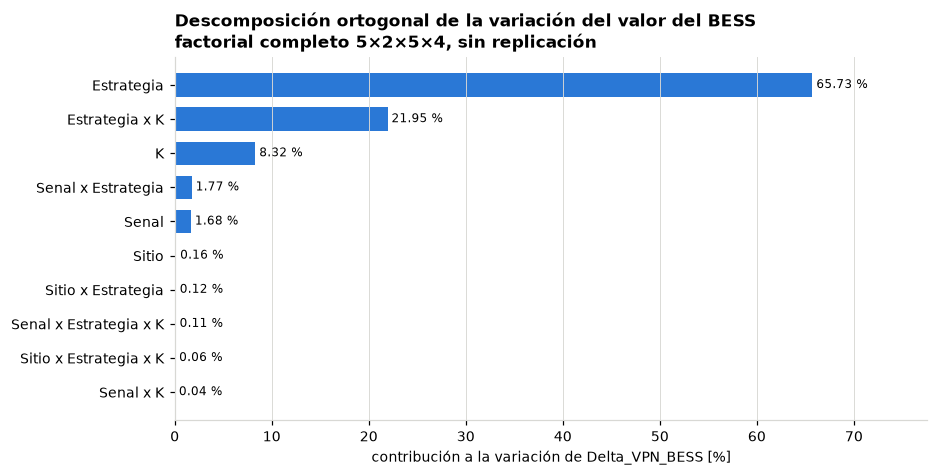

In [6]:
D = EF[EF.Variable == "Delta_VPN_BESS_MUSD"].sort_values("SS", ascending=False)
display(D[["Termino", "SS", "pct", "Orden"]].round(4).reset_index(drop=True))
print("suma de contribuciones: {:.10f} %".format(D.pct.sum()))
assert abs(D.pct.sum() - 100) < 1e-8

top = D.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.6, 4.4))
ax.barh(range(len(top)), top.pct, color="#2a78d6", height=0.68)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.Termino)
for i, v in enumerate(top.pct):
    ax.text(v + 0.4, i, "{:.2f} %".format(v), va="center", fontsize=8)
ax.set_xlabel("contribución a la variación de Delta_VPN_BESS [%]")
ax.set_title("Descomposición ortogonal de la variación del valor del BESS\n"
             "factorial completo 5×2×5×4, sin replicación",
             loc="left", fontweight="bold")
ax.grid(axis="y", visible=False); ax.set_xlim(0, top.pct.max() * 1.18)
plt.tight_layout(); plt.savefig(FIG / "08_1_contribuciones_completo.png"); plt.show()

Los cuatro términos mayores son **Estrategia 52,44 %**, **Estrategia × K
16,39 %**, **Señal × Estrategia 15,21 %** y **K 9,33 %**.

Ese primer número necesita una advertencia inmediata: **la gran contribución de
Estrategia está dominada por la separación de C y F respecto de las reglas
orientadas al usuario.** C y F pueden alejarse mucho de A, B y D —hasta destruir
valor incremental— y esa distancia, no las diferencias entre reglas razonables,
es lo que llena la suma de cuadrados.

Por eso **todavía no se puede concluir que la operación importe más que el
dimensionamiento**. La sección siguiente separa las dos cosas.

## 08.7 · Subfactorial A/B/D

A, B y D son las tres reglas **orientadas al usuario industrial**: no cargan
desde la red, priorizan la energía propia y su objetivo principal es atender la
demanda. C y F responden a una lógica merchant y se conservan en el factorial
completo con ese papel.

La partición es **conceptual, no por desempeño**: separa reglas por el tipo de
decisión que toman, no por lo bien que les fue.

Repetir la descomposición sobre las 120 celdas de A/B/D responde una pregunta
distinta: *entre estrategias razonables para el usuario industrial, ¿cuánto
importa realmente escoger una regla frente a otra?*

,Termino,SS,pct,Orden
0,K,4649.1727,66.3838,1
1,Senal,1962.3359,28.0195,1
2,Sitio,287.8140,4.1096,1
3,Sitio x K,64.1519,0.9160,2
4,Senal x K,18.8000,0.2684,2
5,Estrategia x K,5.9955,0.0856,2
6,Estrategia,4.5970,0.0656,1
7,Sitio x Senal x K,4.4036,0.0629,3
8,Sitio x Senal,3.8338,0.0547,2
9,Senal x Estrategia,1.2778,0.0182,2


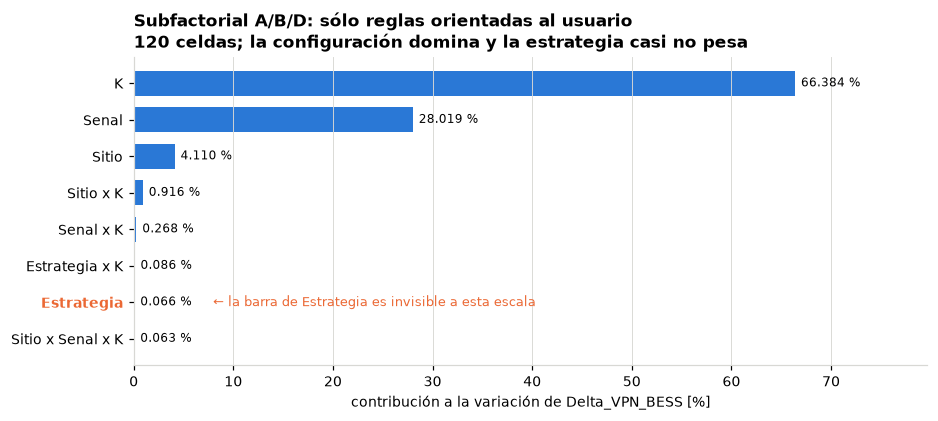

In [7]:
A3 = EF[EF.Variable == "Delta_VPN_BESS_MUSD_ABD"].sort_values("SS", ascending=False)
display(A3[["Termino", "SS", "pct", "Orden"]].round(4).reset_index(drop=True))
assert abs(A3.pct.sum() - 100) < 1e-8

top = A3.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.6, 3.9))
col = ["#eb6834" if t == "Estrategia" else "#2a78d6" for t in top.Termino]
ax.barh(range(len(top)), top.pct, color=col, height=0.68)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.Termino)
for i, v in enumerate(top.pct):
    ax.text(v + 0.6, i, "{:.3f} %".format(v), va="center", fontsize=8)
# La barra de Estrategia mide 0,064 %: es invisible a esta escala, y eso es
# justamente el resultado. Se marca la etiqueta en su color y con una flecha.
i_est = list(top.Termino).index("Estrategia")
ax.get_yticklabels()[i_est].set_color("#eb6834")
ax.get_yticklabels()[i_est].set_fontweight("bold")
ax.text(top.pct.max() * 0.12, i_est,
        "← la barra de Estrategia es invisible a esta escala",
        color="#eb6834", fontsize=8.5, va="center")
ax.set_xlabel("contribución a la variación de Delta_VPN_BESS [%]")
ax.set_title("Subfactorial A/B/D: sólo reglas orientadas al usuario\n"
             "120 celdas; la configuración domina y la estrategia casi no pesa",
             loc="left", fontweight="bold")
ax.grid(axis="y", visible=False); ax.set_xlim(0, top.pct.max() * 1.2)
plt.tight_layout(); plt.savefig(FIG / "08_2_contribuciones_ABD.png"); plt.show()

El resultado se invierte por completo:

| término | factorial completo | subfactorial A/B/D |
|---|---|---|
| Estrategia | 52,44 % | **0,064 %** |
| Configuración K | 9,33 % | **68,06 %** |
| Señal | 0,63 % | 26,00 % |
| Sitio | 0,32 % | 4,26 % |

> **Dentro del espacio experimental evaluado, al comparar únicamente reglas
> orientadas al usuario industrial, la configuración PV+BESS explica una
> fracción muy superior de la variación del valor incremental que la identidad
> de la estrategia.**

La razón entre ambas contribuciones es grande, pero **es una propiedad de este
espacio experimental**, no una propiedad universal: depende de los cuatro
niveles K elegidos, de las dos señales y del rango de recursos cubierto.

## 08.8 · Cuánto separa a las reglas competitivas

Para cada uno de los 40 contextos —sitio × señal × configuración— se mide la
distancia entre la mejor y la peor de A, B y D:

$$\text{Gap}_{ABD} = VPN_{\text{mejor}} - VPN_{\text{peor}}$$

,Gap A/B/D
minimo [%],0.0077
mediana [%],0.7198
media [%],0.6320
p90 [%],1.2487
maximo [%],1.3131
mediana [MUSD],0.6713
maximo [MUSD],1.3876


contextos con gap < 0.5 %:  17 de 40  (42 %)
contextos con gap < 1.0 %:  28 de 40  (70 %)
contextos con gap < 2.0 %:  40 de 40  (100 %)


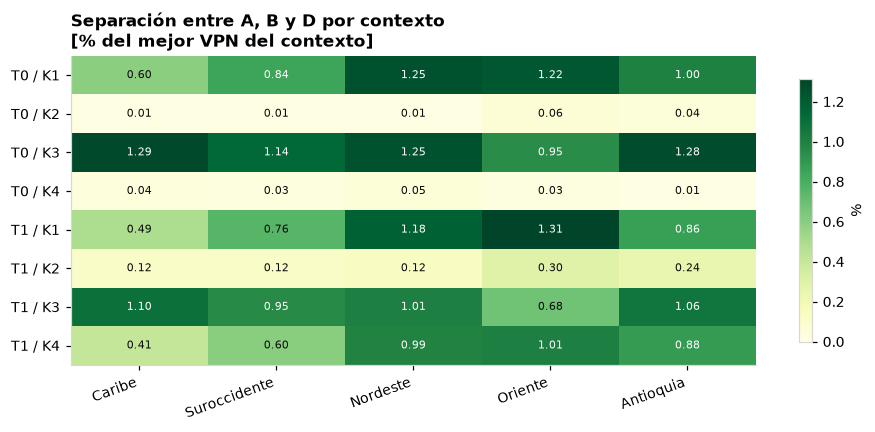

In [8]:
g = GAP.Gap_ABD_pct
resumen_gap = pd.Series({
    "minimo [%]": g.min(), "mediana [%]": g.median(), "media [%]": g.mean(),
    "p90 [%]": g.quantile(0.9), "maximo [%]": g.max(),
    "mediana [MUSD]": GAP.Gap_ABD_MUSD.median(),
    "maximo [MUSD]": GAP.Gap_ABD_MUSD.max()})
display(resumen_gap.to_frame("Gap A/B/D").round(4))
for u in (0.5, 1.0, 2.0):
    print("contextos con gap < {:.1f} %: {:>3} de {}  ({:.0f} %)".format(
        u, int((g < u).sum()), len(g), (g < u).mean() * 100))

piv = GAP.pivot_table(index=["Senal", "K"], columns="Sitio", values="Gap_ABD_pct")
piv = piv[[s for s in SITIOS if s in piv.columns]]
fig, ax = plt.subplots(figsize=(8.6, 4.0))
im = ax.imshow(piv.values, cmap="YlGn", vmin=0, aspect="auto")
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns, rotation=20, ha="right")
ax.set_yticks(range(piv.shape[0]))
ax.set_yticklabels(["{} / {}".format(a, b) for a, b in piv.index])
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, "{:.2f}".format(v), ha="center", va="center", fontsize=7.5,
                color="#0b0b0b" if v < piv.values.max() * 0.6 else "#fcfcfb")
ax.grid(visible=False)
ax.set_title("Separación entre A, B y D por contexto\n"
             "[% del mejor VPN del contexto]", loc="left", fontweight="bold")
fig.colorbar(im, ax=ax, shrink=0.85, label="%")
plt.tight_layout(); plt.savefig(FIG / "08_3_gap_ABD.png"); plt.show()

La mediana es **0,72 %** y el máximo **1,32 %**; los **40 de 40** contextos
quedan por debajo del 2 %.

**Entre estrategias competitivas, la separación económica es pequeña.** El
contexto donde más importa la regla es la configuración representativa K3 bajo
señal cuasi-plana, y aun allí la distancia entre la mejor y la peor de las tres
no llega a 1,32 % del VPN.

## 08.9 · Regret: ganar no es lo mismo que ser distinguible

El *regret* de una regla en un contexto es lo que se pierde por usarla en vez de
la mejor de ese contexto. Separa dos cosas que la cuenta de victorias mezcla:
**ser la regla ganadora** y **ser económicamente casi indistinguible de la
mejor**.

In [9]:
filas = []
for e in COLOR:
    q = REG[REG.Estrategia == e]
    filas.append({"estrategia": e, "victorias": int((q.Regret_MUSD < 1e-9).sum()),
                  "regret medio [%]": q.Regret_pct.mean(),
                  "mediana [%]": q.Regret_pct.median(),
                  "p90 [%]": q.Regret_pct.quantile(0.9),
                  "maximo [%]": q.Regret_pct.max(),
                  "dentro de 0,5 %": int((q.Regret_pct <= 0.5).sum()),
                  "dentro de 1 %": int((q.Regret_pct <= 1.0).sum())})
display(pd.DataFrame(filas).set_index("estrategia").round(3))

,victorias,regret medio [%],mediana [%],p90 [%],maximo [%],"dentro de 0,5 %",dentro de 1 %
estrategia,,,,,,,
A Autoconsumo,8,0.235,0.024,0.622,1.008,32,39
B Merito diario,28,0.012,0.000,0.038,0.123,40,40
C Merchant,0,47.953,50.877,76.251,88.145,0,0
D Merito+Export,4,0.519,0.307,1.249,1.313,21,29
F Merchant reserva,0,31.220,28.235,66.089,72.900,0,9


**B gana 30 de 40 contextos, pero el dato más informativo es otro:** su peor
regret en todo el factorial es **0,157 %**, y está dentro del 0,5 % del mejor en
los **40 de 40** contextos. A y D pierden más veces y siguen siendo cercanas
—39 y 29 contextos dentro del 1 %—.

C y F están en otra escala: regret medio de 36,1 % y 20,0 %, con peores casos de
88,7 % y 73,3 %.

> Entre las heurísticas competitivas, la identidad de la regla ganadora tiene un
> efecto económico pequeño; en cambio, una selección inadecuada de la estrategia
> puede generar pérdidas mucho mayores que la brecha entre la mejor heurística y
> el benchmark operativo.

## 08.10 · Las dos interacciones que importan

De las once interacciones, dos concentran el 31,6 % de la variación y el resto
suma 1,3 %. Se muestran esas dos.

In [10]:
m1 = F.pivot_table(index="Senal", columns="Estrategia", values="Delta_VPN_BESS_MUSD")
m1.columns = [CORTO[c] for c in m1.columns]
print("Señal x Estrategia — contribución {:.2f} %".format(
    EF.loc[(EF.Variable == "Delta_VPN_BESS_MUSD") & (EF.Termino == "Senal x Estrategia"), "pct"].iloc[0]))
display(m1.round(3))

m2 = F.pivot_table(index="K", columns="Estrategia", values="Delta_VPN_BESS_MUSD").loc[ORD_R]
m2.columns = [CORTO[c] for c in m2.columns]
print("Estrategia x K — contribución {:.2f} %".format(
    EF.loc[(EF.Variable == "Delta_VPN_BESS_MUSD") & (EF.Termino == "Estrategia x K"), "pct"].iloc[0]))
display(m2.round(3))

otras = EF[(EF.Variable == "Delta_VPN_BESS_MUSD")
           & (~EF.Termino.isin(["Estrategia", "K", "Senal", "Sitio",
                                "Senal x Estrategia", "Estrategia x K"]))]
print("los {} terminos restantes suman {:.2f} % de la variacion".format(
    len(otras), otras.pct.sum()))

Señal x Estrategia — contribución 1.77 %


,A,B,C,D,F
Senal,,,,,
T0,23.785,23.777,-13.123,23.280,-6.459
T1,31.581,31.991,-19.054,31.533,4.592


Estrategia x K — contribución 21.95 %


,A,B,C,D,F
K,,,,,
K1,27.314,27.486,-40.077,26.665,-31.912
K3,37.296,37.555,-20.898,36.490,-3.769
K2,26.703,26.760,-7.380,26.738,12.816
K4,19.421,19.735,4.001,19.734,19.130


los 9 terminos restantes suman 0.39 % de la variacion


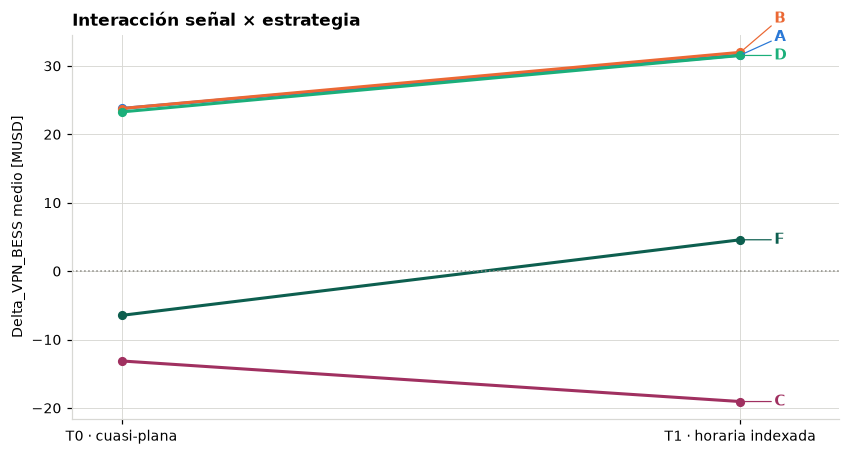

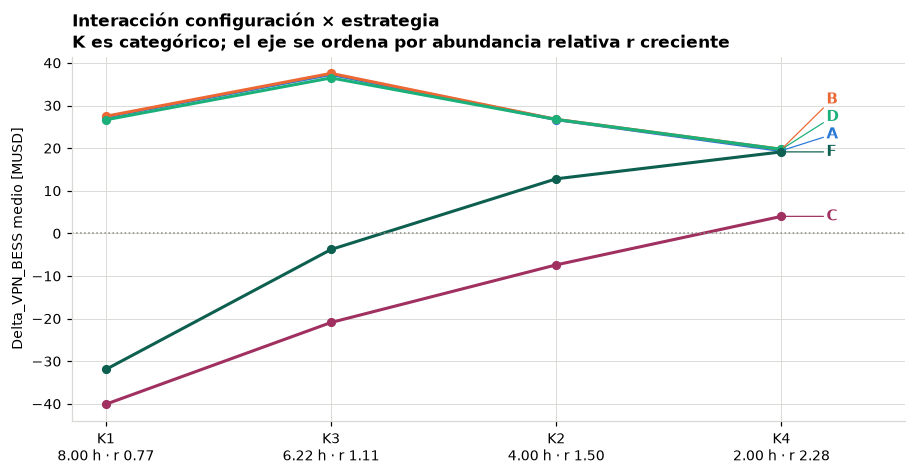

In [11]:
def etiquetar(ax, finales, x_fin, dx, frac=0.048):
    # Etiqueta directa al final de cada línea, separando las que se solapan.
    # La separación mínima se mide sobre el RANGO DEL EJE, no sobre la
    # dispersión de los valores finales: si cuatro series terminan casi juntas
    # su dispersión es diminuta y las etiquetas se montarían igual.
    lo, hi = ax.get_ylim()
    sep = (hi - lo) * frac
    prev = None
    for e, v in sorted(finales.items(), key=lambda kv: kv[1]):
        y = v if prev is None else max(v, prev + sep)
        ax.annotate(CORTO[e], xy=(x_fin, v), xytext=(x_fin + dx, y),
                    color=COLOR[e], va="center", fontweight="bold", fontsize=10,
                    arrowprops=dict(arrowstyle="-", color=COLOR[e], linewidth=0.8,
                                    shrinkA=0, shrinkB=2))
        prev = y

fig, ax = plt.subplots(figsize=(7.8, 4.2))
fin = {}
for e in COLOR:
    q = F[F.Estrategia == e].groupby("Senal").Delta_VPN_BESS_MUSD.mean()
    ax.plot([0, 1], q.loc[["T0", "T1"]], "-o", color=COLOR[e], linewidth=2, markersize=5)
    fin[e] = float(q.loc["T1"])
etiquetar(ax, fin, 1.0, 0.055)
ax.axhline(0, color="#8b8a83", linewidth=1, linestyle=":")
ax.set_xticks([0, 1]); ax.set_xticklabels(["T0 · cuasi-plana", "T1 · horaria indexada"])
ax.set_xlim(-0.08, 1.16); ax.set_ylabel("Delta_VPN_BESS medio [MUSD]")
ax.set_title("Interacción señal × estrategia", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "08_4_senal_estrategia.png"); plt.show()

fig, ax = plt.subplots(figsize=(8.4, 4.4))
x = np.arange(len(ORD_R)); fin = {}
for e in COLOR:
    q = F[F.Estrategia == e].groupby("K").Delta_VPN_BESS_MUSD.mean().loc[ORD_R]
    ax.plot(x, q, "-o", color=COLOR[e], linewidth=2, markersize=5)
    fin[e] = float(q.iloc[-1])
etiquetar(ax, fin, x[-1], 0.20)
ax.axhline(0, color="#8b8a83", linewidth=1, linestyle=":")
ax.set_xticks(x)
ax.set_xticklabels(["{}\n{:.2f} h · r {:.2f}".format(
    c, F[F.K == c].Duracion_h.iloc[0], F[F.K == c].r_medio.mean()) for c in ORD_R])
ax.set_xlim(-0.15, len(ORD_R) - 0.45)
ax.set_ylabel("Delta_VPN_BESS medio [MUSD]")
ax.set_title("Interacción configuración × estrategia\n"
             "K es categórico; el eje se ordena por abundancia relativa r creciente",
             loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "08_5_config_estrategia.png"); plt.show()

Las dos figuras cuentan la misma historia desde ángulos distintos: **A, B y D
trazan perfiles casi superpuestos**, mientras C y F cambian de nivel —y de
signo— al mover la señal o la configuración. Ni la señal ni la configuración
reordenan las reglas razonables; reordenan las merchant.

## 08.11 · El sitio

In [12]:
s = F.groupby("Sitio").Delta_VPN_BESS_MUSD.agg(
    medio="mean", mediana="median", minimo="min", maximo="max")
s["rango entre K"] = (F.groupby(["Sitio", "K"]).Delta_VPN_BESS_MUSD.mean()
                      .groupby("Sitio").agg(lambda x: x.max() - x.min()))
s["dVPN medio A/B/D"] = FA.groupby("Sitio").Delta_VPN_BESS_MUSD.mean()
s["VPN medio [MUSD]"] = F.groupby("Sitio").VPN_MUSD.mean()
display(s.loc[SITIOS].round(3))

pc = EF.set_index(["Variable", "Termino"]).pct
print("contribucion del Sitio:")
print("   sobre Delta_VPN_BESS, factorial completo : {:>6.3f} %".format(
    pc[("Delta_VPN_BESS_MUSD", "Sitio")]))
print("   sobre Delta_VPN_BESS, subfactorial A/B/D : {:>6.3f} %".format(
    pc[("Delta_VPN_BESS_MUSD_ABD", "Sitio")]))
print("   sobre VPN total,      factorial completo : {:>6.3f} %".format(
    pc[("VPN_MUSD", "Sitio")]))
print("   sobre VPN total,      subfactorial A/B/D : {:>6.3f} %".format(
    pc[("VPN_MUSD_ABD", "Sitio")]))

,medio,mediana,minimo,maximo,rango entre K,dVPN medio A/B/D,VPN medio [MUSD]
Sitio,,,,,,,
Caribe,14.056,23.710,-42.262,43.923,16.553,29.250,82.868
Suroccidente,14.353,23.477,-42.466,43.586,15.420,29.437,78.956
Nordeste,12.590,21.232,-42.218,40.167,14.896,26.862,74.584
Oriente,11.865,20.042,-42.477,38.165,15.343,25.288,71.830
Antioquia,13.087,22.340,-42.483,40.900,15.820,27.452,68.005


contribucion del Sitio:
   sobre Delta_VPN_BESS, factorial completo :  0.165 %
   sobre Delta_VPN_BESS, subfactorial A/B/D :  4.110 %
   sobre VPN total,      factorial completo :  5.118 %
   sobre VPN total,      subfactorial A/B/D : 43.764 %


> **El efecto del sitio sobre el valor incremental del BESS es secundario frente
> a configuración y señal, aunque no nulo.**

Hay que distinguir dos cosas que se confunden con facilidad:

- sobre **`Delta_VPN_BESS`** el sitio aporta 0,32 % en el factorial completo y
  4,26 % entre A/B/D. Restar la línea base sin batería elimina casi todo el
  efecto del recurso, porque bajo penetración normalizada el sitio determina el
  tamaño y el CAPEX del PV, y eso afecta por igual al caso con batería y a su
  contrafactual;
- sobre el **VPN total** el sitio aporta 7,71 % y **42,72 %** entre A/B/D.

Dicho de otro modo: **el sitio determina cuánto vale el proyecto, no cuánto
aporta la batería.**

## 08.12 · Conclusiones

1. **El dimensionamiento pesa más que la sofisticación operativa entre reglas
   razonables.** Dentro del espacio experimental evaluado, al comparar
   únicamente reglas orientadas al usuario industrial, la configuración PV+BESS
   explica el 68,06 % de la variación del valor incremental y la identidad de la
   estrategia el 0,064 %.

2. **Escoger mal una estrategia sí destruye valor.** C y F llegan a regrets de
   88,7 % y 73,3 %, y producen los únicos 32 casos con `Delta_VPN_BESS`
   negativo. Ninguna combinación con A, B o D destruye valor incremental: su
   mínimo es +14,30 MUSD.

3. **Afinar entre reglas buenas aporta poco.** La separación entre A, B y D tiene
   mediana de 0,72 % y máximo de 1,32 %, y los 40 contextos quedan bajo el 2 %.
   B gana 30 de 40, pero su valor práctico es que está dentro del 0,5 % del
   mejor en los 40.

4. **La señal económica cambia qué reglas son viables, no cuál conviene entre las
   buenas.** Señal × Estrategia aporta el 15,21 % de la variación: al pasar a la
   señal horaria indexada, A, B y D mejoran unos 7,7 MUSD mientras C cae 28,2.
   Entre A/B/D esa interacción vale 0,008 %.

5. **El sitio decide el tamaño del proyecto, no el aporte de la batería.** Bajo
   penetración normalizada, el recurso fija la potencia PV y su CAPEX —de 100,8
   a 117,3 MWp— y con ello el 42,72 % de la variación del VPN entre A/B/D; sobre
   el valor incremental del BESS su peso baja al 4,26 %.

La pregunta que este cuaderno **no** responde es cuánto separa a una buena
heurística del despacho que conocería el futuro. Eso se mide en
`09_Comparacion_reglas_operativas.ipynb`.